# 📋 QoS Buddy — Prétraitement TelecomTS
## BO2 : Prévention des Ruptures de SLA (B2B)

**Dataset** : `AliMaatouk/TelecomTS` — séries temporelles 5G multi-KPI  
**Objectif** : Prédire à l'avance les violations de contrats SLA B2B  
**KPIs réels** : RSRP, DL_BLER, UL_BLER, DL_MCS, UL_MCS, UL_NPRB, UL_SNR,  
TX_Bytes, RX_Bytes, Estimated_UL_Buffer, PRBs_DL_Current, PRBs_UL_Current,  
PRB_Utilization_DL, PRB_Utilization_UL, DL_NumberOfPackets, UL_NumberOfPackets  

> **Note** : `label` = 100% NaN dans ce dataset → la cible SLA est construite  
> entièrement depuis les règles KPI (percentiles p10/p90).

## 📦 Étape 1 — Imports

In [ ]:
import pandas as pd
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, json, os
warnings.filterwarnings('ignore')

from datasets import load_dataset
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report, roc_auc_score,
    average_precision_score, precision_recall_curve
)
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
np.random.seed(SEED)

C_OK   = '#2ecc71'; C_RISK = '#e74c3c'
C_WARN = '#f39c12'; C_BLUE = '#3498db'
print('✅ Imports OK')

✅ Imports OK


## 📂 Étape 2 — Chargement du dataset TelecomTS

In [ ]:
print('⏳ Chargement AliMaatouk/TelecomTS...')
dataset = load_dataset("AliMaatouk/TelecomTS", data_files={"full": "**/chunked.jsonl"})
sample  = dataset["full"][0]
print(f'✅ Dataset chargé : {len(dataset["full"])} samples')
print(f'Clés disponibles  : {list(sample.keys())}')

# Afficher les KPIs disponibles dans le premier sample
kpis_raw = sample.get('KPIs', {})
if isinstance(kpis_raw, str):
    kpis_raw = json.loads(kpis_raw)
print(f'\nKPIs détectés ({len(kpis_raw)}) :')
for k, v in kpis_raw.items():
    n = len(v) if isinstance(v, list) else '?'
    ex = v[:2] if isinstance(v, list) else v
    print(f'  {k:35s} : {n} pts | ex: {ex}')
print(f'\nLabels : {sample.get("labels", "N/A")}')
print(f'Anomalies : {str(sample.get("anomalies", "N/A"))[:100]}')

⏳ Chargement AliMaatouk/TelecomTS...


README.md: 0.00B [00:00, ?B/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/33 [00:00<?, ?it/s]

chunked.jsonl: 0.00B [00:00, ?B/s]

...

normal/stationary/Zone_C/no_congestion/F(…):   0%|          | 0.00/94.6M [00:00<?, ?B/s]

normal/stationary/Zone_C/no_congestion/T(…):   0%|          | 0.00/94.3M [00:00<?, ?B/s]

normal/stationary/Zone_C/no_congestion/Y(…):   0%|          | 0.00/83.4M [00:00<?, ?B/s]

Generating full split: 0 examples [00:00, ? examples/s]

✅ Dataset chargé : 32000 samples
Clés disponibles  : ['start_time', 'end_time', 'sampling_rate', 'KPIs', 'description', 'anomalies', 'statistics', 'labels', 'QnA']

KPIs détectés (18) :
  RSRP                                : 128 pts | ex: [-73.0, -73.0]
  DL_BLER                             : 128 pts | ex: [1e-05, 1.0000000000000004e-05]
  DL_MCS                              : 128 pts | ex: [7.0, 7.0]
  UL_BLER                             : 128 pts | ex: [0.0865019999999999, 0.0873595]
  UL_MCS                              : 128 pts | ex: [17.0, 17.0]
  UL_NPRB                             : 128 pts | ex: [20.77, 24.09]
  UL_SNR                              : 128 pts | ex: [19.48, 22.62]
  TX_Bytes                            : 128 pts | ex: [443817.0, 436519.0]
  RX_Bytes                            : 128 pts | ex: [4837.0, 6388.0]
  Estimated_UL_Buffer                 : 128 pts | ex: [3576.87, 4057.87]
  PRBs_DL_Current                     : 128 pts | ex: [65.47, 62.29]
  PRBs_UL_Curre

## 🔄 Étape 3 — Extraction & mise à plat des séries

In [ ]:
KPI_NAMES = list(kpis_raw.keys()) if isinstance(kpis_raw, dict) else []
print(f'KPIs à extraire : {KPI_NAMES}')

def flatten_sample(sample: dict, kpi_names: list, sample_id: int) -> pd.DataFrame:
    """Convertit un chunk TelecomTS en DataFrame (1 ligne = 1 instant)."""
    raw = sample.get('KPIs', {})
    if isinstance(raw, str):
        try: raw = json.loads(raw)
        except: raw = {}

    n_pts = max((len(v) for v in raw.values() if isinstance(v, list)), default=0)
    if n_pts == 0:
        return pd.DataFrame()

    try:
        idx = pd.date_range(start=sample.get('start_time'), end=sample.get('end_time'), periods=n_pts)
    except Exception:
        idx = pd.RangeIndex(n_pts)

    rows = []
    for i in range(n_pts):
        row = {'series_id': sample_id, 'timestamp': idx[i]}
        for kpi in kpi_names:
            s = raw.get(kpi, [])
            row[kpi] = s[i] if isinstance(s, list) and i < len(s) else np.nan
        # label toujours NaN dans ce dataset — on ignore
        rows.append(row)
    return pd.DataFrame(rows)

print('⏳ Extraction des samples...')
N_MAX   = 500
n_total = len(dataset['full'])
n_load  = min(N_MAX, n_total)
all_dfs, errors = [], 0

for i in range(n_load):
    try:
        s   = dataset['full'][i]
        sid = s.get('id', i) if isinstance(s, dict) else i
        df_ = flatten_sample(s, KPI_NAMES, sid)
        if len(df_) > 0:
            all_dfs.append(df_)
    except Exception:
        errors += 1
    if (i+1) % 100 == 0:
        print(f'  {i+1}/{n_load}...')

df_raw = pd.concat(all_dfs, ignore_index=True)
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'], errors='coerce')
print(f'\n✅ {n_load} samples | {errors} erreurs | Shape: {df_raw.shape}')
df_raw.head(3)

KPIs à extraire : ['RSRP', 'DL_BLER', 'DL_MCS', 'UL_BLER', 'UL_MCS', 'UL_NPRB', 'UL_SNR', 'TX_Bytes', 'RX_Bytes', 'Estimated_UL_Buffer', 'PRBs_DL_Current', 'PRBs_UL_Current', 'PRB_Utilization_DL', 'PRB_Utilization_UL', 'UL_Protocol', 'UL_NumberOfPackets', 'DL_Protocol', 'DL_NumberOfPackets']
⏳ Extraction des samples...
  100/500...
  200/500...
  300/500...
  400/500...
  500/500...

✅ 500 samples | 0 erreurs | Shape: (64000, 20)


,series_id,timestamp,RSRP,DL_BLER,DL_MCS,UL_BLER,UL_MCS,UL_NPRB,UL_SNR,TX_Bytes,RX_Bytes,Estimated_UL_Buffer,PRBs_DL_Current,PRBs_UL_Current,PRB_Utilization_DL,PRB_Utilization_UL,UL_Protocol,UL_NumberOfPackets,DL_Protocol,DL_NumberOfPackets
0,0,2025-01-01 00:05:33.000,-73.0,0.00001,7.0,0.086502,17.0,20.77,19.48,443817.0,4837.0,3576.87,65.47,1.96,61.7641,1.8492,TCP,73.0,TCP,274.0
1,0,2025-01-01 00:05:33.100,-73.0,0.00001,7.0,0.087360,17.0,24.09,22.62,436519.0,6388.0,4057.87,62.29,2.74,58.7641,2.5850,TCP,85.0,TCP,297.0
2,0,2025-01-01 00:05:33.200,-73.0,0.00000,7.0,0.080182,17.0,24.92,23.64,443817.0,6388.0,3908.73,64.14,1.08,60.5094,1.0190,TCP,99.0,TCP,238.0


## 🔍 Étape 4 — Exploration

In [ ]:
# Colonnes KPI numériques (exclure series_id, timestamp, label, meta_*)
KPI_COLS = [
    c for c in df_raw.columns
    if c not in ('timestamp', 'series_id')
    and not c.startswith('meta_')
    and pd.api.types.is_numeric_dtype(df_raw[c])
]
print(f'KPI_COLS ({len(KPI_COLS)}) : {KPI_COLS}')
print()
df_raw[KPI_COLS].describe().round(4)

KPI_COLS (16) : ['RSRP', 'DL_BLER', 'DL_MCS', 'UL_BLER', 'UL_MCS', 'UL_NPRB', 'UL_SNR', 'TX_Bytes', 'RX_Bytes', 'Estimated_UL_Buffer', 'PRBs_DL_Current', 'PRBs_UL_Current', 'PRB_Utilization_DL', 'PRB_Utilization_UL', 'UL_NumberOfPackets', 'DL_NumberOfPackets']



,RSRP,DL_BLER,DL_MCS,UL_BLER,UL_MCS,UL_NPRB,UL_SNR,TX_Bytes,RX_Bytes,Estimated_UL_Buffer,PRBs_DL_Current,PRBs_UL_Current,PRB_Utilization_DL,PRB_Utilization_UL,UL_NumberOfPackets,DL_NumberOfPackets
count,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000,64000.0000
mean,-84.1314,0.0068,6.6744,0.0738,15.3559,13.1417,19.5473,143919.2537,2605.2502,2746.1307,23.7717,0.7657,24.4670,1.6588,115.8627,191.1861
std,10.2767,0.0152,1.2709,0.0671,5.9957,9.6961,3.6505,182917.6986,3479.6411,16100.2364,28.4282,1.1375,28.6691,4.7187,726.0073,702.7400
min,-126.0000,0.0000,0.0000,0.0000,0.0000,1.6828,0.9242,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,-92.8423,0.0000,7.0000,0.0022,9.0000,5.0000,18.9852,0.0000,209.0000,0.0000,0.0000,0.0500,0.0000,0.0472,0.0000,0.0000
50%,-79.0000,0.0008,7.0000,0.0712,15.0000,9.5480,20.3550,22606.5000,1409.0000,252.5400,5.2400,0.3000,9.3349,0.4813,15.0300,26.0000
75%,-75.0000,0.0048,7.0000,0.1088,17.0000,18.8200,21.7333,354592.0000,4545.2500,1026.2800,63.0800,1.2200,59.5094,1.4152,66.0000,158.8410
max,-66.4900,0.2363,9.0000,0.6068,27.0000,91.4443,57.4850,635687.0000,98783.0000,205303.9264,106.0000,34.3600,100.0000,54.8497,10647.0799,8166.6913


Series([], )


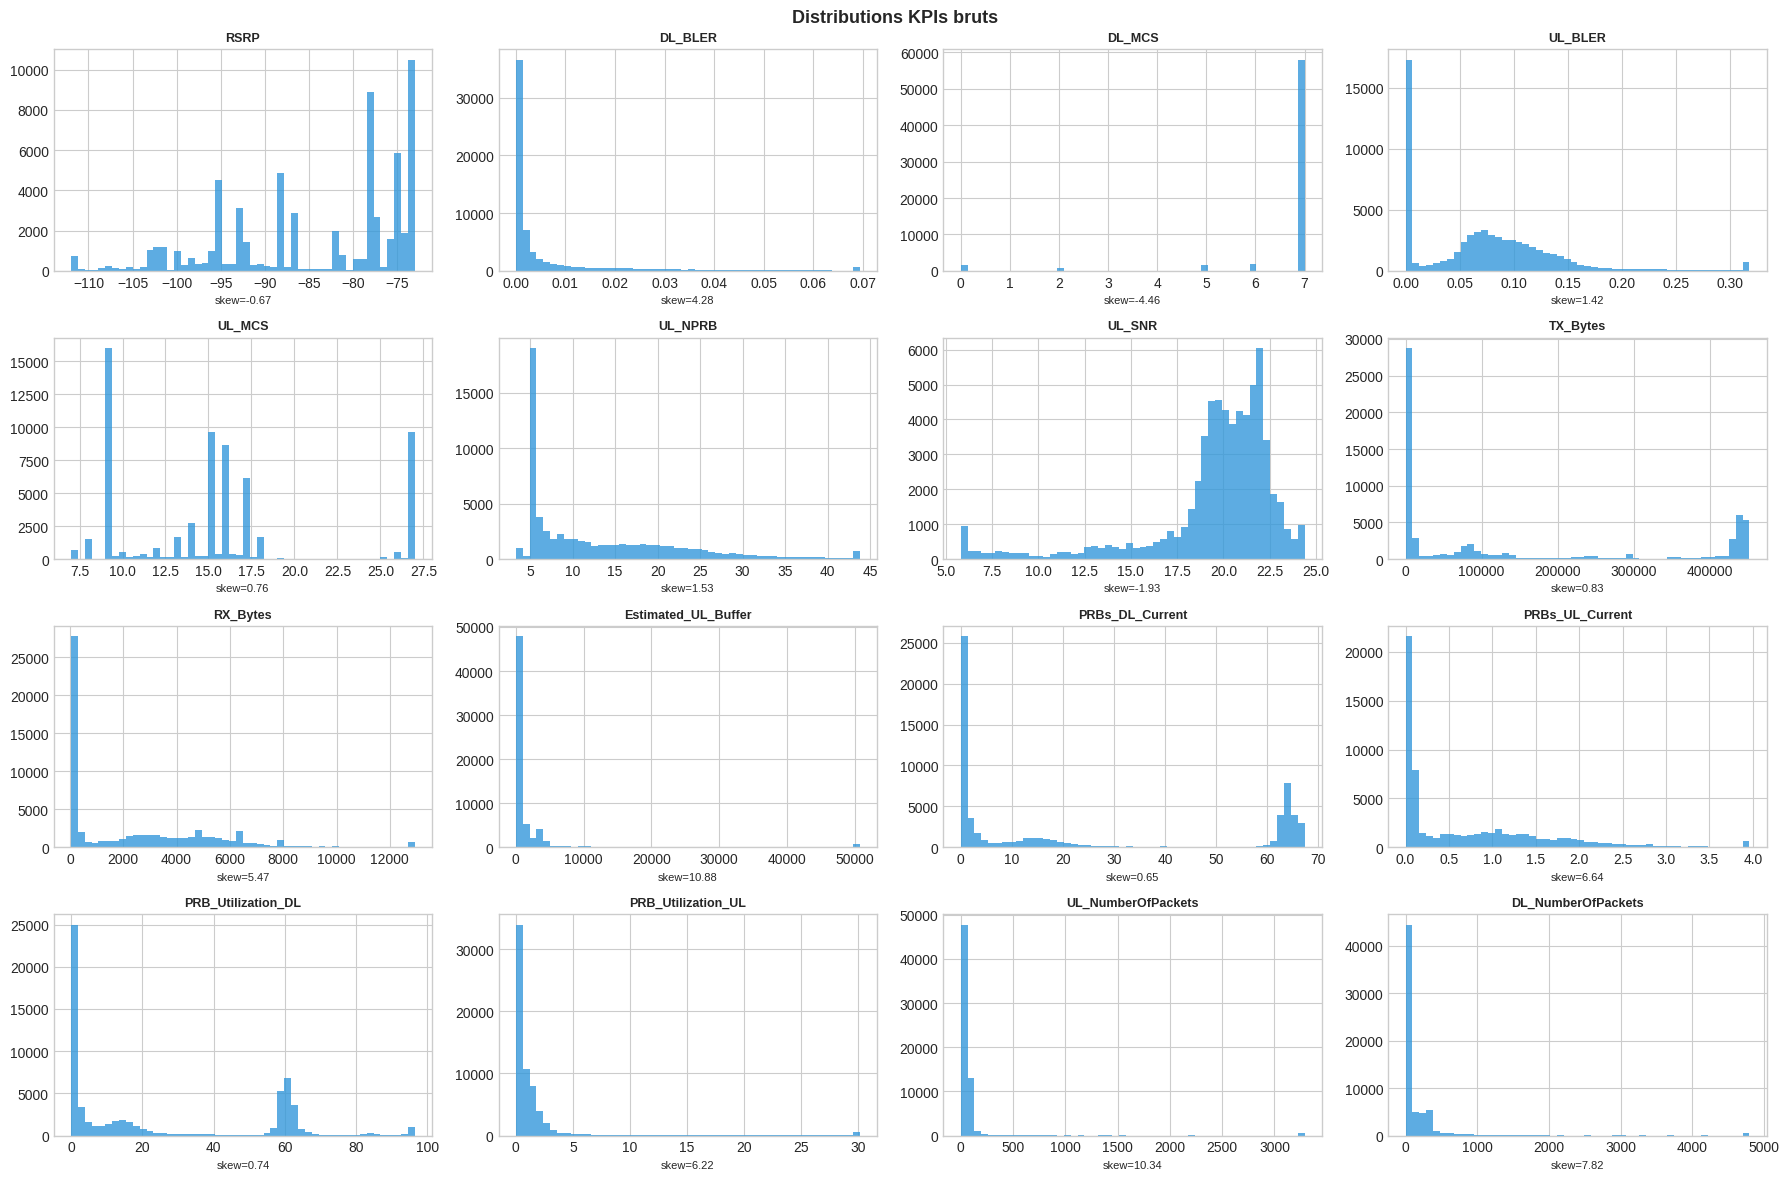

In [ ]:
# Valeurs manquantes
mv = df_raw[KPI_COLS].isnull().mean() * 100
print(mv[mv > 0].sort_values(ascending=False).to_string() or '✅ Aucun NaN')

# Distributions
n_kpi  = len(KPI_COLS)
n_cols = 4
n_rows = (n_kpi + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = np.array(axes).flatten()
for i, col in enumerate(KPI_COLS):
    d = df_raw[col].dropna()
    axes[i].hist(d.clip(*d.quantile([.01,.99])), bins=50, color=C_BLUE, alpha=.8)
    axes[i].set_title(col, fontsize=9, fontweight='bold')
    axes[i].set_xlabel(f'skew={d.skew():.2f}', fontsize=8)
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Distributions KPIs bruts', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.savefig('kpi_distributions.png', dpi=120); plt.show()

## 🧹 Étape 5 — Nettoyage

In [ ]:
n_before = len(df_raw)
df_clean = df_raw.drop_duplicates(subset=['series_id', 'timestamp'])
n_dup    = n_before - len(df_clean)
print(f'Doublons supprimés : {n_dup}')

# Valeurs négatives impossibles → NaN
n_neg_total = 0
df_clean = df_clean.copy()
for col in KPI_COLS:
    n_neg = (df_clean[col] < 0).sum()
    if n_neg > 0:
        df_clean.loc[df_clean[col] < 0, col] = np.nan
        n_neg_total += n_neg
print(f'Valeurs négatives → NaN : {n_neg_total}')

# Winsorisation p99.5
winsor_report = []
for col in KPI_COLS:
    cap = df_clean[col].quantile(.995)
    n_c = (df_clean[col] > cap).sum()
    if n_c > 0:
        df_clean.loc[df_clean[col] > cap, col] = cap
        winsor_report.append(col)
print(f'Winsorisation (p99.5) : {len(winsor_report)} colonnes')

# Imputation (tri temporel par série)
df_clean = df_clean.sort_values(['series_id', 'timestamp'])
cols_to_drop = []
for col in KPI_COLS:
    pct = df_clean[col].isna().mean() * 100
    if pct == 0:
        continue
    elif pct < 20:
        df_clean[col] = (df_clean.groupby('series_id')[col]
                         .transform(lambda s: s.interpolate('linear', limit_direction='both')
                                               .fillna(s.median())))
        print(f'  {col:35s} {pct:.1f}% → interpolation')
    else:
        cols_to_drop.append(col)
        print(f'  {col:35s} {pct:.1f}% → SUPPRIMÉE (trop de NaN)')

if cols_to_drop:
    df_clean = df_clean.drop(columns=cols_to_drop)
    KPI_COLS = [c for c in KPI_COLS if c not in cols_to_drop]

print(f'\n✅ df_clean : {df_clean.shape} | NaN restants : {df_clean[KPI_COLS].isnull().sum().sum()}')

Doublons supprimés : 0
Valeurs négatives → NaN : 64000
Winsorisation (p99.5) : 14 colonnes
  RSRP                                100.0% → SUPPRIMÉE (trop de NaN)

✅ df_clean : (64000, 19) | NaN restants : 0


## 🏷️ Étape 6 — Construction de la cible SLA

**Stratégie** : les labels sont 100% NaN → on construit `sla_breach_risk`  
directement depuis les KPIs avec des **seuils p10/p90 calculés sur les données réelles**.

| Type de KPI | Logique métier | Seuil |
|---|---|---|
| BLER, Buffer, PRB_Utilization | Valeur élevée = problème | > p90 |
| RSRP, SNR, MCS, Bytes, Packets, NPRB, PRBs | Valeur basse = problème | < p10 |

In [ ]:
# ── 6.1 Stats réelles des KPIs ───────────────────────────────────────────────
print('=== STATISTIQUES KPIs RÉELS ===')
kpi_stats = {}
for col in KPI_COLS:
    s = df_clean[col].dropna()
    kpi_stats[col] = {k: float(v) for k, v in {
        'min': s.min(), 'p10': s.quantile(.10), 'p50': s.median(),
        'p90': s.quantile(.90), 'p99': s.quantile(.99), 'max': s.max(), 'std': s.std()
    }.items()}
    print(f'  {col:30s} | p10={kpi_stats[col]["p10"]:8.3f} | '
          f'p50={kpi_stats[col]["p50"]:8.3f} | p90={kpi_stats[col]["p90"]:8.3f}')

# ── 6.2 Définition des seuils SLA par logique métier 5G ─────────────────────
# Règle : si un KPI dégradé → violation SLA
# Direction déterminée colonne par colonne selon le nom réel
ABOVE_KPIS = ['bler', 'buffer', 'utilization']   # valeur élevée = problème
BELOW_KPIS = ['rsrp', 'snr', 'mcs', 'bytes', 'packets', 'nprb', 'prbs']  # valeur basse = problème

print('\n=== SEUILS SLA (p10/p90 sur données réelles) ===')
SLA_THRESHOLDS = {}   # col → (seuil, direction, description)
for col in KPI_COLS:
    cl = col.lower()
    if any(k in cl for k in ABOVE_KPIS):
        direction, thresh = 'above', kpi_stats[col]['p90']
    elif any(k in cl for k in BELOW_KPIS):
        direction, thresh = 'below', kpi_stats[col]['p10']
    else:
        direction, thresh = 'above', kpi_stats[col]['p90']   # défaut: p90

    SLA_THRESHOLDS[col] = (thresh, direction,
        f'{col} {">" if direction=="above" else "<"} '
        f'p{"90" if direction=="above" else "10"}={thresh:.4f}')
    print(f'  {col:30s} | {direction:5s} | seuil={thresh:10.4f}')

print(f'\n→ {len(SLA_THRESHOLDS)} règles SLA définies')

=== STATISTIQUES KPIs RÉELS ===
  DL_BLER                        | p10=   0.000 | p50=   0.001 | p90=   0.022
  DL_MCS                         | p10=   7.000 | p50=   7.000 | p90=   7.000
  UL_BLER                        | p10=   0.000 | p50=   0.071 | p90=   0.145
  UL_MCS                         | p10=   9.000 | p50=  15.000 | p90=  27.000
  UL_NPRB                        | p10=   5.000 | p50=   9.548 | p90=  26.290
  UL_SNR                         | p10=  15.128 | p50=  20.355 | p90=  22.500
  TX_Bytes                       | p10=   0.000 | p50=22606.500 | p90=440168.000
  RX_Bytes                       | p10= 114.000 | p50=1409.000 | p90=6342.000
  Estimated_UL_Buffer            | p10=   0.000 | p50= 252.540 | p90=3796.400
  PRBs_DL_Current                | p10=   0.000 | p50=   5.240 | p90=  65.200
  PRBs_UL_Current                | p10=   0.000 | p50=   0.300 | p90=   1.970
  PRB_Utilization_DL             | p10=   0.000 | p50=   9.335 | p90=  61.764
  PRB_Utilization_UL         

In [ ]:
# ── 6.3 Application colonne par colonne (pas de pattern matching) ─────────────
df_labeled = df_clean.copy()
df_labeled['sla_breach_risk']  = 0
df_labeled['n_sla_violations'] = 0

print('Application des règles SLA :')
applied = []
for col, (thresh, direction, desc) in SLA_THRESHOLDS.items():
    if col not in df_labeled.columns:
        continue
    mask  = (df_labeled[col] > thresh) if direction == 'above' else (df_labeled[col] < thresh)
    n_viol = int(mask.sum())
    if n_viol > 0:
        df_labeled['sla_breach_risk']  = df_labeled['sla_breach_risk']  | mask.astype(int)
        df_labeled['n_sla_violations'] += mask.astype(int)
        pct = n_viol / len(df_labeled) * 100
        print(f'  [{col}] {desc} → {n_viol} viol. ({pct:.1f}%)')
        applied.append(col)

df_labeled['sla_breach_risk'] = df_labeled['sla_breach_risk'].astype(int).clip(0, 1)
df_labeled['sla_risk_level']  = pd.cut(
    df_labeled['n_sla_violations'], bins=[-1, 0, 1, 2, 100],
    labels=['OK', 'Risque faible', 'Risque élevé', 'Critique']
)

rate = df_labeled['sla_breach_risk'].mean() * 100
print(f'\n=== CIBLE SLA FINALE ===')
print(df_labeled['sla_breach_risk'].value_counts().to_string())
print(f'Taux de violation : {rate:.1f}% | Règles appliquées : {len(applied)}/{len(SLA_THRESHOLDS)}')
assert df_labeled['sla_breach_risk'].sum() > 0, "ERREUR: aucune violation — vérifier KPI_COLS"
print('✅ Cible SLA valide')

Application des règles SLA :
  [DL_BLER] DL_BLER > p90=0.0224 → 6400 viol. (10.0%)
  [DL_MCS] DL_MCS < p10=7.0000 → 6064 viol. (9.5%)
  [UL_BLER] UL_BLER > p90=0.1454 → 6400 viol. (10.0%)
  [UL_MCS] UL_MCS < p10=9.0000 → 2184 viol. (3.4%)
  [UL_NPRB] UL_NPRB < p10=5.0000 → 1334 viol. (2.1%)
  [UL_SNR] UL_SNR < p10=15.1277 → 6399 viol. (10.0%)
  [RX_Bytes] RX_Bytes < p10=114.0000 → 6371 viol. (10.0%)
  [Estimated_UL_Buffer] Estimated_UL_Buffer > p90=3796.4000 → 6399 viol. (10.0%)
  [PRB_Utilization_DL] PRB_Utilization_DL > p90=61.7641 → 6098 viol. (9.5%)
  [PRB_Utilization_UL] PRB_Utilization_UL > p90=2.6322 → 6358 viol. (9.9%)

=== CIBLE SLA FINALE ===
sla_breach_risk
0    32562
1    31438
Taux de violation : 49.1% | Règles appliquées : 10/15
✅ Cible SLA valide


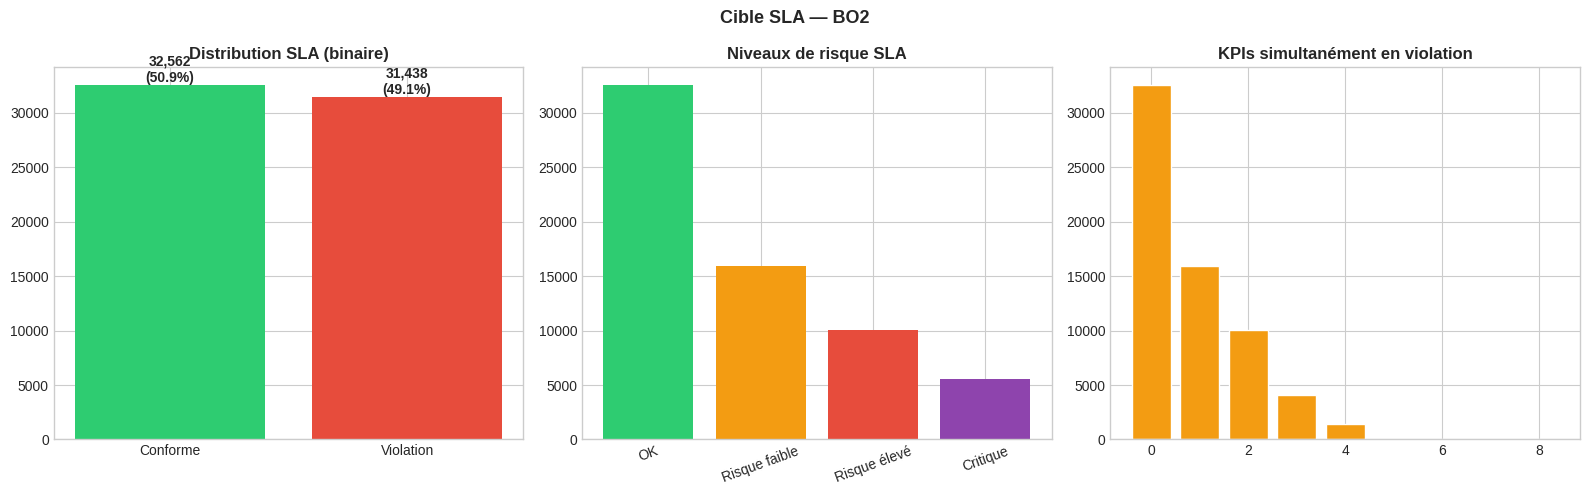

In [ ]:
# Visualisation cible SLA
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

vc = df_labeled['sla_breach_risk'].value_counts().sort_index()
axes[0].bar(['Conforme', 'Violation'], vc.values, color=[C_OK, C_RISK])
for i, v in enumerate(vc.values):
    axes[0].text(i, v + len(df_labeled)*.005, f'{v:,}\n({v/len(df_labeled)*100:.1f}%)',
                 ha='center', fontweight='bold')
axes[0].set_title('Distribution SLA (binaire)', fontweight='bold')

rl = df_labeled['sla_risk_level'].value_counts()
axes[1].bar(rl.index, rl.values, color=[C_OK, C_WARN, C_RISK, '#8e44ad'][:len(rl)])
axes[1].set_title('Niveaux de risque SLA', fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)

axes[2].hist(df_labeled['n_sla_violations'], bins=range(0, 10),
             color=C_WARN, edgecolor='white', align='left', rwidth=.8)
axes[2].set_title('KPIs simultanément en violation', fontweight='bold')

plt.suptitle('Cible SLA — BO2', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('sla_distribution.png', dpi=120); plt.show()

## ⚙️ Étape 7 — Feature Engineering TS-safe

Les features sont calculées **par série** (`groupby series_id`) pour éviter toute fuite.

**IMPORTANT** : `sla_proximity` et `prealert` utilisent maintenant les clés de  
`SLA_THRESHOLDS` qui sont les **noms exacts de colonnes** (plus de pattern matching).

In [ ]:
def build_features(df: pd.DataFrame, kpi_cols: list, sla_thresholds: dict,
                   windows=[3, 6, 12], lags=[1, 2, 3], group_col='series_id') -> pd.DataFrame:
    df = df.copy().sort_values([group_col, 'timestamp'])
    g  = df.groupby(group_col, sort=False)

    # ── B : Proximité aux seuils SLA (colonne par colonne, clé = nom exact) ──
    for col, (thresh, direction, _) in sla_thresholds.items():
        if col not in df.columns:
            continue
        t = thresh if thresh != 0 else 1e-6
        if direction == 'above':
            # ratio : 1 = au seuil, >1 = en violation
            df[f'sla_prox_{col}'] = df[col] / (abs(t) + 1e-9)
        else:
            # ratio : 1 = au seuil, >1 = en violation
            df[f'sla_prox_{col}'] = (abs(t) + 1e-9) / (df[col].abs() + 1e-9)

    # ── C/D : Rolling + lags + dérivées (par série) ───────────────────────────
    for col in kpi_cols:
        gc = g[col]
        for lag in lags:
            df[f'{col}_lag{lag}'] = gc.shift(lag)
        df[f'{col}_diff1']   = gc.diff(1)
        df[f'{col}_pct1']    = gc.pct_change(1).replace([np.inf, -np.inf], np.nan)

        for w in windows:
            r = gc.rolling(w, min_periods=1)
            df[f'{col}_rmean{w}'] = r.mean().reset_index(level=0, drop=True)
            df[f'{col}_rstd{w}']  = r.std().reset_index(level=0, drop=True).fillna(0)
            df[f'{col}_rmax{w}']  = r.max().reset_index(level=0, drop=True)
            df[f'{col}_rmin{w}']  = r.min().reset_index(level=0, drop=True)

        df[f'{col}_trend'] = df[col] - df[f'{col}_rmean{windows[0]}']

    # ── E : Flags pré-alerte (20% avant le seuil) ────────────────────────────
    n_prealert = pd.Series(0, index=df.index)
    for col, (thresh, direction, _) in sla_thresholds.items():
        if col not in df.columns:
            continue
        margin = abs(thresh) * 0.20
        if direction == 'above':
            flag = (df[col] > (thresh - margin)).astype(int)
        else:
            flag = (df[col] < (thresh + margin)).astype(int)
        df[f'prealert_{col}'] = flag
        n_prealert += flag
    df['n_prealert'] = n_prealert

    # ── F : Temporel ──────────────────────────────────────────────────────────
    ts = pd.to_datetime(df['timestamp'], errors='coerce')
    if pd.api.types.is_datetime64_any_dtype(ts):
        df['hour']        = ts.dt.hour
        df['hour_sin']    = np.sin(2 * np.pi * df['hour'] / 24)
        df['hour_cos']    = np.cos(2 * np.pi * df['hour'] / 24)
        df['dayofweek']   = ts.dt.dayofweek
        df['is_business'] = ((df['hour'] >= 8) & (df['hour'] <= 18) & (df['dayofweek'] < 5)).astype(int)

    return df

print('⏳ Feature engineering...')
df_features = build_features(df_labeled, KPI_COLS, SLA_THRESHOLDS)
new_cols    = [c for c in df_features.columns if c not in df_labeled.columns]
print(f'✅ {len(new_cols)} nouvelles features | Shape: {df_features.shape}')

# Résumé par groupe
for grp, pat in [('B sla_prox', 'sla_prox_'), ('C/D rolling/lags', '_rmean'),
                  ('E prealerts', 'prealert_'), ('F temporel', 'hour')]:
    n = sum(1 for c in df_features.columns if pat in c)
    print(f'  [{grp}] : {n} features')

⏳ Feature engineering...
✅ 306 nouvelles features | Shape: (64000, 328)
  [B sla_prox] : 15 features
  [C/D rolling/lags] : 45 features
  [E prealerts] : 15 features
  [F temporel] : 3 features


## 📋 Étape 8 — Feature matrix & Corrélation avec SLA

In [ ]:
EXCLUDE = {'series_id', 'timestamp', 'sla_breach_risk', 'sla_risk_level', 'n_sla_violations'}
FEAT_COLS = [c for c in df_features.columns
             if c not in EXCLUDE and pd.api.types.is_numeric_dtype(df_features[c])]

# Features brutes (on garde les NaN ici; l'imputation sera fit UNIQUEMENT sur le train)
X_raw = df_features[FEAT_COLS].replace([np.inf, -np.inf], np.nan)
y     = df_features['sla_breach_risk'].astype(int)

print(f'Feature matrix : {X_raw.shape}')
print(f'Cible sla_breach_risk : {y.value_counts().to_dict()}')
print(f'NaN restants (brut) : {X_raw.isna().sum().sum()}')
print(f'Variance cible : {y.var():.6f}  (0 = constante — problème!)')
assert y.var() > 0, "ERREUR : sla_breach_risk est constante → pipeline SLA cassé"
print('✅ Cible non-constante → corrélations calculables')

# Pour les corrélations uniquement (pas pour l'entraînement)
X_corr = X_raw.fillna(X_raw.median(numeric_only=True))


Feature matrix : (64000, 321)
Cible sla_breach_risk : {0: 32562, 1: 31438}
NaN restants (brut) : 212357
Variance cible : 0.249927  (0 = constante — problème!)
✅ Cible non-constante → corrélations calculables


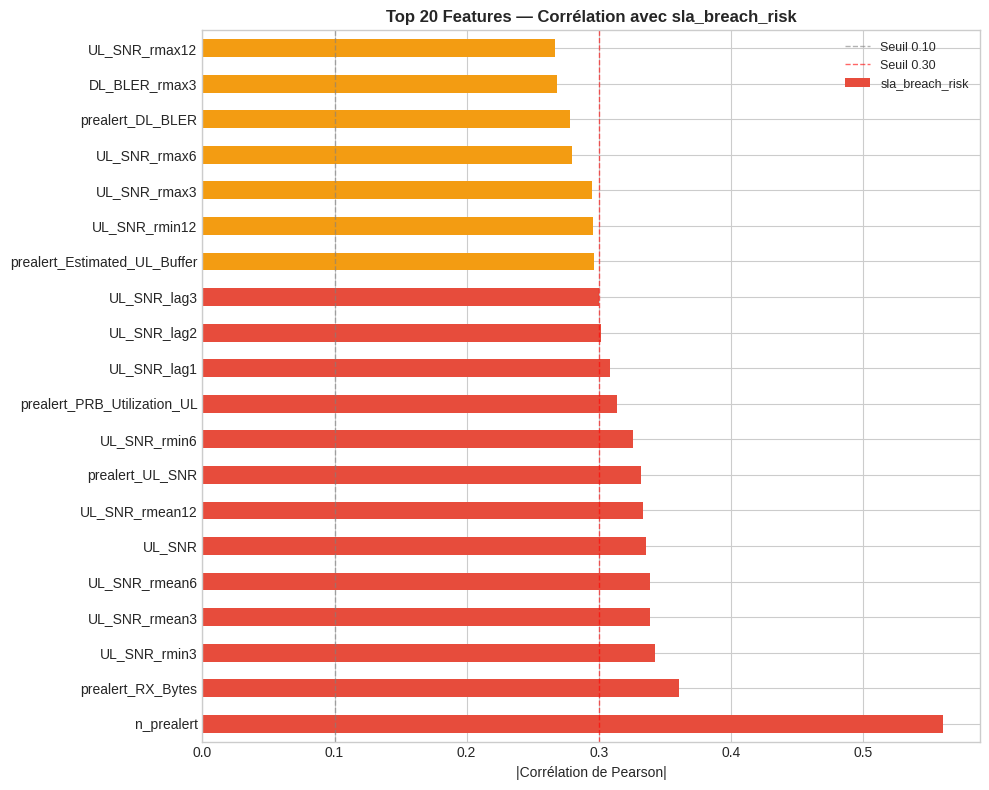


Top 10 features :
n_prealert                     0.5604
prealert_RX_Bytes              0.3603
UL_SNR_rmin3                   0.3426
UL_SNR_rmean3                  0.3389
UL_SNR_rmean6                  0.3384
UL_SNR                         0.3355
UL_SNR_rmean12                 0.3338
prealert_UL_SNR                0.3321
UL_SNR_rmin6                   0.3260
prealert_PRB_Utilization_UL    0.3140


In [ ]:
# Corrélation |Pearson| avec sla_breach_risk
corr = pd.concat([X_corr, y.rename('sla_breach_risk')], axis=1).corr()['sla_breach_risk']
corr = corr.drop('sla_breach_risk').abs().sort_values(ascending=False)

top20 = corr.head(20)
colors = [C_RISK if v > .3 else C_WARN if v > .1 else C_BLUE for v in top20.values]

fig, ax = plt.subplots(figsize=(10, 8))
top20.plot(kind='barh', ax=ax, color=colors, edgecolor='none')
ax.axvline(.1, color='gray', ls='--', lw=1, alpha=.6, label='Seuil 0.10')
ax.axvline(.3, color='red',  ls='--', lw=1, alpha=.6, label='Seuil 0.30')
ax.set_title('Top 20 Features — Corrélation avec sla_breach_risk',
             fontweight='bold', fontsize=12)
ax.set_xlabel('|Corrélation de Pearson|')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('feature_correlation_sla.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nTop 10 features :')
print(corr.head(10).round(4).to_string())

## ✂️ Étape 9 — Split temporel & Scaling

In [ ]:
# Split temporel par groupe (80/20, ordre chronologique préservé)
train_idx, val_idx = [], []
for _, gdf in df_features.groupby('series_id', sort=False):
    n   = len(gdf)
    cut = int(np.floor(n * .80))
    train_idx.extend(gdf.index[:cut])
    val_idx.extend(gdf.index[cut:])

X_tr, X_val = X_raw.loc[train_idx], X_raw.loc[val_idx]
y_tr, y_val = y.loc[train_idx], y.loc[val_idx]

# ✅ Imputation fit sur train uniquement (évite fuite)
imputer = SimpleImputer(strategy="median")
X_tr_i  = imputer.fit_transform(X_tr)
X_val_i = imputer.transform(X_val)

# Scaling fit sur train uniquement
scaler  = RobustScaler()
X_tr_s  = scaler.fit_transform(X_tr_i)
X_val_s = scaler.transform(X_val_i)

print(f'Train : {X_tr.shape}  | violations: {y_tr.sum()} ({y_tr.mean()*100:.1f}%)')
print(f'Val   : {X_val.shape} | violations: {y_val.sum()} ({y_val.mean()*100:.1f}%)')
print(f'✅ Imputer+RobustScaler fit sur train uniquement')


Train : (51000, 321)  | violations: 25070 (49.2%)
Val   : (13000, 321) | violations: 6368 (49.0%)
✅ Imputer+RobustScaler fit sur train uniquement


## 🔮 Étape 10 — Cibles Early Warning (15/30/60 min)

In [ ]:
def add_ew_targets(df, breach_col='sla_breach_risk', group_col='series_id',
                   time_col='timestamp', horizons=[15, 30, 60]):
    df = df.copy().sort_values([group_col, time_col])

    # Inférer le pas temporel (minutes)
    deltas   = df.groupby(group_col)[time_col].diff().dropna().dt.total_seconds()
    step_min = float(np.median(deltas) / 60) if len(deltas) > 0 else 1.0
    if step_min <= 0 or np.isnan(step_min):
        step_min = 1.0
    print(f'Pas temporel estimé : {step_min:.2f} min/obs')

    g = df.groupby(group_col, sort=False)[breach_col]

    for H in horizons:
        steps   = max(1, int(round(H / step_min)))
        col_out = f'breach_within_{H}min'

        # ✅ Max(breach) dans le FUTUR: t+1 ... t+steps
        df[col_out] = (
            g.transform(lambda s: s.shift(-1)[::-1].rolling(steps, min_periods=1).max()[::-1])
             .fillna(0).astype(int)
        )

        print(f'  {col_out} : {steps} steps | taux={df[col_out].mean()*100:.2f}%')

    return df

df_features = add_ew_targets(df_features)
print('✅ Cibles early warning créées')


Pas temporel estimé : 0.00 min/obs
  breach_within_15min : 9000 steps | taux=92.61%
  breach_within_30min : 18000 steps | taux=92.61%
  breach_within_60min : 36000 steps | taux=92.61%
✅ Cibles early warning créées


## 🤖 Étape 11 — Modèle baseline (Early Warning 60 min)

In [ ]:
TARGET_EW = 'breach_within_60min'
y_ew      = df_features[TARGET_EW].astype(int)

# Utilise le split existant, mais si VAL mono-classe -> fallback split par séries
y_tr_ew   = y_ew.loc[train_idx]
y_val_ew  = y_ew.loc[val_idx]

if y_val_ew.nunique() < 2:
    print("⚠️ Validation mono-classe détectée pour EW (ROC-AUC/F1 non fiables).")
    print("➡️ Fallback: split par séries (GroupShuffleSplit) pour avoir des classes dans train/val.")

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    tr_pos, va_pos = next(gss.split(df_features, groups=df_features['series_id']))
    train_idx = df_features.index[tr_pos]
    val_idx   = df_features.index[va_pos]

    # Refit preprocessing sur le nouveau split
    X_tr, X_val = X_raw.loc[train_idx], X_raw.loc[val_idx]
    y_tr, y_val = y.loc[train_idx], y.loc[val_idx]

    imputer = SimpleImputer(strategy="median")
    X_tr_i  = imputer.fit_transform(X_tr)
    X_val_i = imputer.transform(X_val)

    scaler  = RobustScaler()
    X_tr_s  = scaler.fit_transform(X_tr_i)
    X_val_s = scaler.transform(X_val_i)

    y_tr_ew  = y_ew.loc[train_idx]
    y_val_ew = y_ew.loc[val_idx]

print(f"EW train: {y_tr_ew.value_counts().to_dict()}")
print(f"EW val  : {y_val_ew.value_counts().to_dict()}")
assert y_tr_ew.nunique() == 2, "Train EW mono-classe -> impossible d'entraîner correctement"
assert y_val_ew.nunique() == 2, "Val EW mono-classe -> métriques non fiables"

# Sample weights (équilibrage sans SMOTE)
pos = max(1, int(y_tr_ew.sum()))
neg = max(1, int((y_tr_ew == 0).sum()))
sw  = np.where(y_tr_ew.values == 1, neg/pos, 1.0)

clf = HistGradientBoostingClassifier(
    learning_rate=0.05, max_depth=6, max_iter=300, random_state=SEED
)
clf.fit(X_tr_s, y_tr_ew.values, sample_weight=sw)

proba_val = clf.predict_proba(X_val_s)[:, 1]
roc = roc_auc_score(y_val_ew, proba_val)
ap  = average_precision_score(y_val_ew, proba_val)
print(f'ROC-AUC={roc:.4f} | PR-AUC={ap:.4f}')

# ✅ Seuil optimal F1 (index correct : thr a une taille = len(prec)-1)
prec, rec, thr = precision_recall_curve(y_val_ew, proba_val)
f1  = 2*prec*rec / (prec + rec + 1e-9)

if len(thr) > 0:
    best_i = int(np.nanargmax(f1[:-1]))   # on ignore le dernier point
    bth    = float(thr[best_i])
else:
    best_i = 0
    bth    = 0.5

print(f'Seuil F1-opt = {bth:.3f} | F1={f1[best_i]:.3f} (P={prec[best_i]:.3f} R={rec[best_i]:.3f})')
print(classification_report(y_val_ew, (proba_val >= bth).astype(int), digits=3))

# Score sur tout le dataset (sans fuite : imputer/scaler fit sur train)
X_all_s = scaler.transform(imputer.transform(X_raw))
proba_all = clf.predict_proba(X_all_s)[:, 1]
df_features['proba_breach_60min'] = proba_all

def to_alert(p):
    if p >= .80: return 'CRITIQUE'
    if p >= .60: return 'ÉLEVÉ'
    if p >= .30: return 'À SURVEILLER'
    return 'OK'

df_features['alert_level_60min'] = df_features['proba_breach_60min'].map(to_alert)

os.makedirs('outputs', exist_ok=True)
joblib.dump({'model': clf, 'scaler': scaler, 'imputer': imputer,
             'features': FEAT_COLS, 'threshold': bth},
            'outputs/bo2_ew_hgb_60min.joblib')
print('✅ Modèle sauvegardé : outputs/bo2_ew_hgb_60min.joblib')


EW train: {1: 49617, 0: 1383}
EW val  : {1: 9656, 0: 3344}
ROC-AUC=0.8043 | PR-AUC=0.8990
Seuil F1-opt = 0.868 | F1=0.880 (P=0.812 R=0.961)
              precision    recall  f1-score   support

           0      0.760     0.359     0.488      3344
           1      0.812     0.961     0.880      9656

    accuracy                          0.806     13000
   macro avg      0.786     0.660     0.684     13000
weighted avg      0.799     0.806     0.779     13000

✅ Modèle sauvegardé : outputs/bo2_ew_hgb_60min.joblib


## 🧪 Étape 11b — Entraînement multi-modèles & Comparaison

On entraîne **4 modèles supplémentaires** sur la même cible  :
- **RandomForestClassifier** (ensemble d'arbres, robuste aux outliers)
- **LogisticRegression** (baseline linéaire, interprétable)
- **XGBClassifier** (boosting par gradient, si xgboost installé)
- **LGBMClassifier** (boosting léger, si lightgbm installé)

Puis on compare : ROC-AUC, PR-AUC, F1-optimal et temps d'entraînement.

In [ ]:
# ── Imports supplémentaires pour multi-modèles ───────────────────────────
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# XGBoost (optionnel)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("⚠️  xgboost non installé → pip install xgboost")

# LightGBM (optionnel)
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("⚠️  lightgbm non installé → pip install lightgbm")

print("XGBoost disponible :", HAS_XGB)
print("LightGBM disponible :", HAS_LGBM)
print("✅ Imports multi-modèles OK")


In [ ]:
# ── Définition du catalogue de modèles ───────────────────────────────────
# Poids d'équilibrage (même logique que HGB)
pos_ew = max(1, int(y_tr_ew.sum()))
neg_ew = max(1, int((y_tr_ew == 0).sum()))
sw_ew  = np.where(y_tr_ew.values == 1, neg_ew / pos_ew, 1.0)

MODEL_CATALOG = {
    "HGB (baseline)":  clf,   # déjà entraîné en Étape 11
    "RandomForest":    RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced",
        n_jobs=-1, random_state=SEED
    ),
    "LogisticRegression": LogisticRegression(
        C=0.1, class_weight="balanced",
        max_iter=1000, random_state=SEED, n_jobs=-1
    ),
}

if HAS_XGB:
    MODEL_CATALOG["XGBoost"] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        scale_pos_weight=neg_ew / pos_ew,
        eval_metric="logloss", use_label_encoder=False,
        random_state=SEED, n_jobs=-1
    )

if HAS_LGBM:
    MODEL_CATALOG["LightGBM"] = LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=63,
        class_weight="balanced",
        random_state=SEED, n_jobs=-1, verbose=-1
    )

print(f"Modèles à évaluer : {list(MODEL_CATALOG.keys())}")


In [ ]:
# ── Entraînement & évaluation de tous les modèles ────────────────────────
results = []
trained_models = {}

for name, model in MODEL_CATALOG.items():
    print(f"
🏋️  Entraînement : {name}")
    t0 = time.time()

    # HGB déjà fit → on passe directement à l'éval
    if name == "HGB (baseline)":
        trained_models[name] = model
    else:
        # RandomForest et LightGBM supportent sample_weight
        if name in ("RandomForest", "LightGBM"):
            model.fit(X_tr_s, y_tr_ew.values, sample_weight=sw_ew)
        elif name == "XGBoost":
            model.fit(X_tr_s, y_tr_ew.values,
                      sample_weight=sw_ew,
                      eval_set=[(X_val_s, y_val_ew.values)],
                      verbose=False)
        else:  # LogisticRegression (class_weight=balanced)
            model.fit(X_tr_s, y_tr_ew.values)
        trained_models[name] = model

    elapsed = time.time() - t0

    # Prédictions
    proba = model.predict_proba(X_val_s)[:, 1]
    roc   = roc_auc_score(y_val_ew, proba)
    ap    = average_precision_score(y_val_ew, proba)

    # Seuil F1-optimal
    prec_c, rec_c, thr_c = precision_recall_curve(y_val_ew, proba)
    f1_c = 2 * prec_c * rec_c / (prec_c + rec_c + 1e-9)
    if len(thr_c) > 0:
        bi   = int(np.nanargmax(f1_c[:-1]))
        best_thr = float(thr_c[bi])
        best_f1  = float(f1_c[bi])
        best_p   = float(prec_c[bi])
        best_r   = float(rec_c[bi])
    else:
        best_thr = 0.5; best_f1 = best_p = best_r = float("nan")

    results.append({
        "Modèle":    name,
        "ROC-AUC":   round(roc,    4),
        "PR-AUC":    round(ap,     4),
        "F1-opt":    round(best_f1, 3),
        "Précision": round(best_p,  3),
        "Rappel":    round(best_r,  3),
        "Seuil":     round(best_thr, 3),
        "Temps (s)": round(elapsed, 2),
    })

    print(f"   ROC-AUC={roc:.4f} | PR-AUC={ap:.4f} | F1-opt={best_f1:.3f} | {elapsed:.1f}s")

df_results = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
print("
📊 Tableau comparatif :")
print(df_results.to_string(index=False))


In [ ]:
# ── Visualisation comparative ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Comparaison des modèles — Early Warning 60 min", fontsize=14, fontweight="bold")

metrics = ["ROC-AUC", "PR-AUC", "F1-opt"]
colors  = [C_BLUE, C_WARN, C_RISK]

for ax, metric, color in zip(axes, metrics, colors):
    df_sorted = df_results.sort_values(metric, ascending=True)
    bars = ax.barh(df_sorted["Modèle"], df_sorted[metric],
                   color=color, alpha=0.85, edgecolor="white")
    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(f"{metric} par modèle", fontsize=12)
    ax.set_xlim(0, 1.0)
    for bar, val in zip(bars, df_sorted[metric]):
        ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
                f"{val:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("outputs/multi_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Graphique sauvegardé : outputs/multi_model_comparison.png")


In [ ]:
# ── Courbes PR de tous les modèles ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
palette = [C_BLUE, C_RISK, C_WARN, C_OK, "#9b59b6"]

for (name, model), color in zip(trained_models.items(), palette):
    proba = model.predict_proba(X_val_s)[:, 1]
    prec_c, rec_c, _ = precision_recall_curve(y_val_ew, proba)
    ap_c = average_precision_score(y_val_ew, proba)
    ax.plot(rec_c, prec_c, label=f"{name} (PR-AUC={ap_c:.3f})",
            color=color, linewidth=2)

baseline_pos = y_val_ew.mean()
ax.axhline(baseline_pos, linestyle="--", color="grey", alpha=0.6,
           label=f"Baseline aléatoire ({baseline_pos:.3f})")
ax.set_xlabel("Rappel", fontsize=12)
ax.set_ylabel("Précision", fontsize=12)
ax.set_title("Courbes Précision-Rappel — Tous les modèles", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("outputs/pr_curves_all_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Courbes PR sauvegardées : outputs/pr_curves_all_models.png")


In [ ]:
# ── Sélection & sauvegarde du meilleur modèle ────────────────────────────
best_row   = df_results.iloc[0]
best_name  = best_row["Modèle"]
best_model = trained_models[best_name]

print(f"🏆 Meilleur modèle : {best_name}")
print(f"   ROC-AUC = {best_row['ROC-AUC']}")
print(f"   PR-AUC  = {best_row['PR-AUC']}")
print(f"   F1-opt  = {best_row['F1-opt']}")

# Score tout le dataset avec le meilleur modèle
best_proba_all = best_model.predict_proba(
    scaler.transform(imputer.transform(X_raw))
)[:, 1]
df_features["proba_breach_60min_best"] = best_proba_all
df_features["alert_level_60min_best"]  = df_features["proba_breach_60min_best"].map(to_alert)

# Sauvegarder tous les modèles entraînés + résultats
os.makedirs("outputs", exist_ok=True)
joblib.dump({
    "models":    trained_models,
    "best_name": best_name,
    "scaler":    scaler,
    "imputer":   imputer,
    "features":  FEAT_COLS,
    "threshold": float(best_row["Seuil"]),
    "results_df": df_results
}, "outputs/bo2_ew_multi_models.joblib")

# Export CSV du tableau comparatif
df_results.to_csv("outputs/multi_model_results.csv", index=False)
print("✅ Tous les modèles sauvegardés : outputs/bo2_ew_multi_models.joblib")
print("✅ Résultats CSV : outputs/multi_model_results.csv")


## 📊 Étape 12 — Export Dashboard

In [ ]:
os.makedirs('outputs', exist_ok=True)

pred_cols = [c for c in [
    'sla_breach_risk', 'sla_risk_level', 'n_sla_violations',
    'breach_within_15min', 'breach_within_30min', 'breach_within_60min',
    'proba_breach_60min', 'alert_level_60min'
] if c in df_features.columns]

base_cols = [c for c in ['series_id', 'timestamp'] if c in df_features.columns]
fact_cols = base_cols + KPI_COLS[:20] + pred_cols
fact_bo2  = df_features[fact_cols].copy()
fact_bo2['timestamp'] = pd.to_datetime(fact_bo2['timestamp'], errors='coerce')

def save_df(df, name):
    path = f'outputs/{name}'
    try:
        df.to_parquet(path + '.parquet', index=False)
        print(f'✅ {name}.parquet')
    except Exception:
        df.to_csv(path + '.csv', index=False)
        print(f'✅ {name}.csv')

save_df(fact_bo2, 'fact_bo2_early_warning')

# Dim temps
if pd.api.types.is_datetime64_any_dtype(df_features['timestamp']):
    dim_time = (df_features[['timestamp']].drop_duplicates()
                .assign(date=lambda d: d['timestamp'].dt.date.astype(str),
                        hour=lambda d: d['timestamp'].dt.hour,
                        dayofweek=lambda d: d['timestamp'].dt.dayofweek))
    save_df(dim_time, 'dim_time')

# Full features (pour ré-entraînement offline)
df_exp = df_features.copy()
df_exp['timestamp'] = df_exp['timestamp'].astype(str)
for col in df_exp.select_dtypes('category').columns:
    df_exp[col] = df_exp[col].astype(str)
save_df(df_exp, 'telecomts_bo2_features_full')
print('✅ Exports terminés → dossier outputs/')

✅ fact_bo2_early_warning.parquet
✅ dim_time.parquet
✅ telecomts_bo2_features_full.parquet
✅ Exports terminés → dossier outputs/


## ✅ Récapitulatif

In [ ]:
print('╔' + '═'*70 + '╗')
print('║  QoS BUDDY — BO2 Early Warning — TelecomTS                          ║')
print('╠' + '═'*70 + '╣')
print(f'''
  DATASET
    Source    : AliMaatouk/TelecomTS (5G)
    Brut      : {df_raw.shape[0]:,} obs × {df_raw.shape[1]} cols
    Features  : {df_features.shape[0]:,} obs × {len(FEAT_COLS)} features

  NETTOYAGE
    Doublons supprimés   : {n_dup}
    Valeurs neg → NaN    : {n_neg_total}
    Winsorisation p99.5  : {len(winsor_report)} cols
    Cols supprimées      : {cols_to_drop}

  CIBLE SLA (p10/p90 sur données réelles)
    Règles définies      : {len(SLA_THRESHOLDS)}
    Taux violation       : {df_labeled["sla_breach_risk"].mean()*100:.1f}%

  EARLY WARNING
    Horizons : 15min / 30min / 60min
    Modèle   : HistGradientBoostingClassifier

  EXPORTS → outputs/
    fact_bo2_early_warning.(parquet|csv)
    dim_time.(parquet|csv)
    telecomts_bo2_features_full.(parquet|csv)
    bo2_ew_hgb_60min.joblib
''')
print('╚' + '═'*70 + '╝')
print('→ Brancher Power BI / Qlik sur outputs/fact_bo2_early_warning')

╔══════════════════════════════════════════════════════════════════════╗
║  QoS BUDDY — BO2 Early Warning — TelecomTS                          ║
╠══════════════════════════════════════════════════════════════════════╣

  DATASET
    Source    : AliMaatouk/TelecomTS (5G)
    Brut      : 64,000 obs × 20 cols
    Features  : 64,000 obs × 321 features

  NETTOYAGE
    Doublons supprimés   : 0
    Valeurs neg → NaN    : 64000
    Winsorisation p99.5  : 14 cols
    Cols supprimées      : ['RSRP']

  CIBLE SLA (p10/p90 sur données réelles)
    Règles définies      : 15
    Taux violation       : 49.1%

  EARLY WARNING
    Horizons : 15min / 30min / 60min
    Modèle   : HistGradientBoostingClassifier

  EXPORTS → outputs/
    fact_bo2_early_warning.(parquet|csv)
    dim_time.(parquet|csv)
    telecomts_bo2_features_full.(parquet|csv)
    bo2_ew_hgb_60min.joblib

╚══════════════════════════════════════════════════════════════════════╝
→ Brancher Power BI / Qlik sur outputs/fact_bo2_early_warnin